### Statewide residential extension — summary

Combines the 5 IECC-zone residential reconstructions (`residential_2A/2B/3A/3B/4B.ipynb`) into one comparison, and cross-checks the new statewide methodology against the already-validated Coast-only pipeline.

**Scope of this pass** (agreed before starting, see the plan):
- Residential (ResStock) for all 5 IECC climate zones covering all 254 Texas counties and 3,426 buses.
- Commercial (ComStock) stays **Coast-only** — the statewide ZCTA-to-bus mapping needed for the other 4 zones was not provided, only the tract-level (residential) mapping. To be added once that file is available, without redoing this work.
- Full ERCOT-column validation (per-zone or statewide total) is **not attempted here** — it would compare an incomplete stack (residential only, no commercial, no industrial) against a complete one for 4 of the 5 zones. Left as a documented follow-up.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

exports = Path("../../loadcurves/exports")
statewide_dir = Path("..")
metrics_dir = statewide_dir / "metrics"
exports_out_dir = statewide_dir / "exports"

ZONES = ["2A", "2B", "3A", "3B", "4B"]
ZONE_DESC = {
    "2A": "Very Hot-Humid (incl. Coast)", "2B": "Hot-Dry",
    "3A": "Warm-Humid (DFW/North/East TX)", "3B": "Warm-Dry (West TX/Permian)",
    "4B": "Mixed-Dry (Far West/El Paso)",
}


#### 1. Honest R2 across all 5 zones, one comparison table

In [2]:
cv_frames = []
for zone in ZONES:
    df = pd.read_csv(metrics_dir / f"seasonal_cv_{zone}.csv")
    cv_frames.append(df)

cv_all = pd.concat(cv_frames, ignore_index=True)
pivot = cv_all.pivot(index="Building_Type", columns="Zone", values="Mean_R2")[ZONES]
pivot.loc["Zone mean"] = pivot.mean()
pivot.round(3)


Zone,2A,2B,3A,3B,4B
Building_Type,,,,,
mobile_home,0.780,0.513,0.644,0.487,0.705
multi-family_with_2_-_4_units,0.818,0.396,0.654,0.558,0.148
multi-family_with_5plus_units,0.892,0.697,0.748,0.741,0.610
single-family_attached,0.764,0.505,0.570,0.553,0.383
single-family_detached,0.750,0.169,0.592,0.058,0.328
Zone mean,0.801,0.456,0.642,0.479,0.435


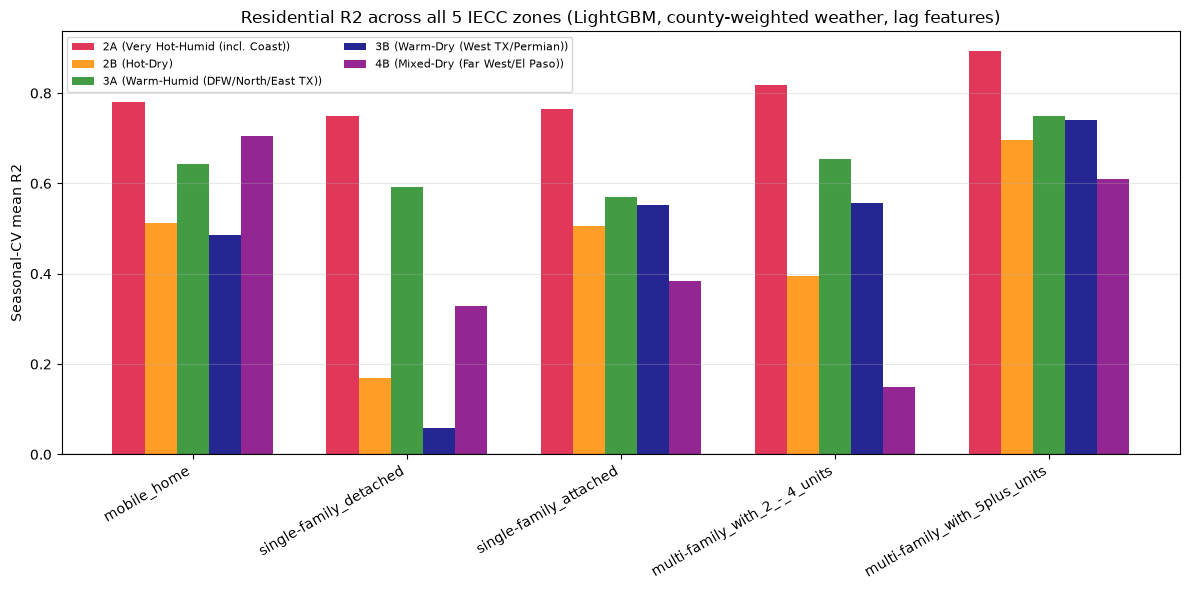

Zone-mean R2, ranked:
Zone
2A    0.8007
3A    0.6417
3B    0.4792
2B    0.4559
4B    0.4348
Name: Zone mean, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(cv_all["Building_Type"].unique()))
building_types = cv_all["Building_Type"].unique()
width = 0.15
colors = {"2A": "crimson", "2B": "darkorange", "3A": "forestgreen", "3B": "navy", "4B": "purple"}

for i, zone in enumerate(ZONES):
    zone_data = cv_all[cv_all["Zone"] == zone].set_index("Building_Type").reindex(building_types)["Mean_R2"]
    ax.bar(x + (i - 2) * width, zone_data, width, label=f"{zone} ({ZONE_DESC[zone]})", color=colors[zone], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(building_types, rotation=30, ha="right")
ax.set_ylabel("Seasonal-CV mean R2")
ax.set_title("Residential R2 across all 5 IECC zones (LightGBM, county-weighted weather, lag features)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(fontsize=8, ncol=2)
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("Zone-mean R2, ranked:")
print(pivot.loc["Zone mean"].sort_values(ascending=False).round(4))


#### 2. Cross-check: new statewide methodology vs. already-validated Coast pipeline

The old 200-bus Coast grid and the new 3,426-bus statewide grid don't share bus IDs and aren't reliably matchable bus-to-bus (verified in `00_zone_mapping.ipynb`: only 72/200 old buses have a new-grid bus within 1km — a denser, different grid, not an extension of the old one). Cross-checking instead at the **county aggregate** level: sum the new 2A-zone reconstruction restricted to the original 12 Coast counties, and compare to the already-validated Coast-only reconstruction.

**Important caveat**: the new 2A run uses a weather blend weighted across all 79 zone-2A counties (Harris ~29.5% weight), not the Coast-specific 12-county blend (Harris ~67% weight) used in `weather_correction.ipynb`. Some divergence is therefore expected and informative in its own right — it is a real test of how much a coarser, zone-wide weather blend costs relative to a locally-tuned one for the same sub-region, not just a reproducibility check.

In [4]:
bus_to_zone = pd.read_csv(statewide_dir / "bus_zone_master.csv", dtype={"COUNTYFP": str})
bus_to_zone["COUNTYFP"] = bus_to_zone["COUNTYFP"].str.zfill(3)
bus_to_zone["Bus_Number"] = bus_to_zone["Bus_Number"].astype(str)

coast_counties = pd.read_csv(statewide_dir / "original_coast_counties.csv", dtype=str)["county_fips"].tolist()

coast_buses_new = bus_to_zone[
    (bus_to_zone["iecc_zone"] == "2A") & (bus_to_zone["COUNTYFP"].isin(coast_counties))
]["Bus_Number"].unique()
print(f"New-grid buses inside the 12 original Coast counties: {len(coast_buses_new)}")

new_2a = pd.read_csv(exports_out_dir / "residential_bus_load_profiles_8760_2A.csv", index_col=0, parse_dates=True)
new_2a.columns = new_2a.columns.astype(str)
cols_present = [c for c in coast_buses_new if c in new_2a.columns]
new_coast_subset_total_mw = new_2a[cols_present].sum(axis=1) / 1000

old_coast = pd.read_csv(exports / "final_bus_load_profiles_8760_featureeng.csv", index_col=0, parse_dates=True)
old_coast_total_mw = old_coast.sum(axis=1) / 1000

print(f"\nNew methodology (2A-blend weather), Coast-county subset ({len(cols_present)} buses):")
print(f"  Peak: {new_coast_subset_total_mw.max():,.1f} MW  |  Annual mean: {new_coast_subset_total_mw.mean():,.1f} MW")
print(f"\nOld methodology (Coast-specific weather), original 200-bus Coast pipeline:")
print(f"  Peak: {old_coast_total_mw.max():,.1f} MW  |  Annual mean: {old_coast_total_mw.mean():,.1f} MW")

common_idx = new_coast_subset_total_mw.index.intersection(old_coast_total_mw.index)
shape_corr = new_coast_subset_total_mw.loc[common_idx].corr(old_coast_total_mw.loc[common_idx])
print(f"\nShape correlation (Pearson) between the two independent methodologies: {shape_corr:.4f}")


New-grid buses inside the 12 original Coast counties: 1505



New methodology (2A-blend weather), Coast-county subset (1505 buses):
  Peak: 11,552.6 MW  |  Annual mean: 4,895.1 MW

Old methodology (Coast-specific weather), original 200-bus Coast pipeline:
  Peak: 10,084.0 MW  |  Annual mean: 4,260.3 MW

Shape correlation (Pearson) between the two independent methodologies: 0.9965


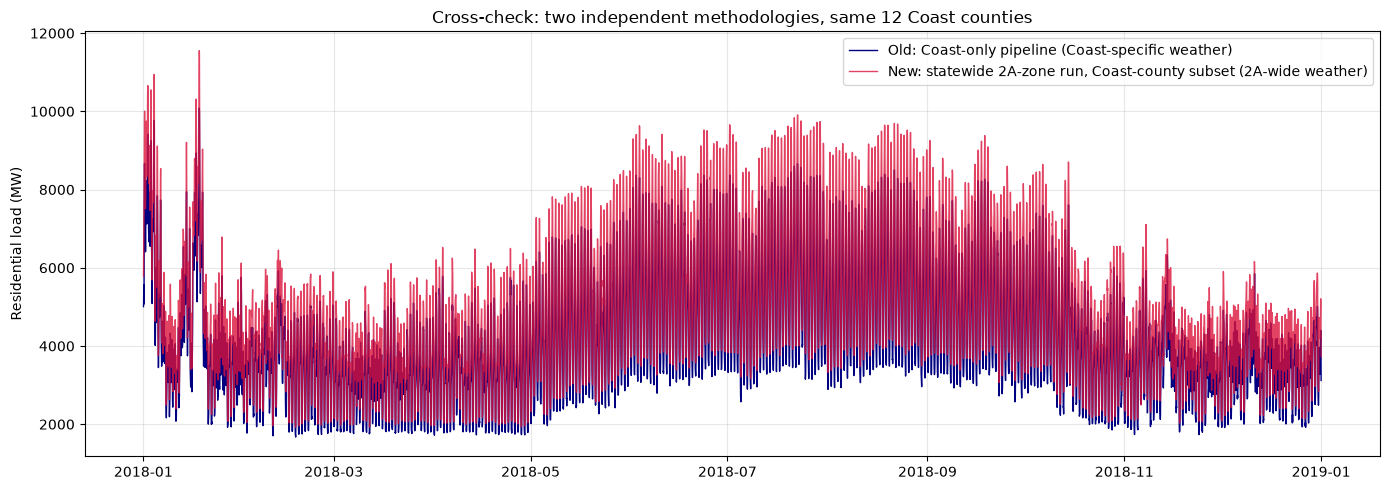

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(old_coast_total_mw.index, old_coast_total_mw, label="Old: Coast-only pipeline (Coast-specific weather)", color="navy", linewidth=1)
ax.plot(new_coast_subset_total_mw.index, new_coast_subset_total_mw, label="New: statewide 2A-zone run, Coast-county subset (2A-wide weather)", color="crimson", linewidth=1, alpha=0.8)
ax.set_ylabel("Residential load (MW)")
ax.set_title("Cross-check: two independent methodologies, same 12 Coast counties")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 3. Texas-wide residential total (directional only — not ERCOT-validated)

Sums all 5 zones' residential reconstructions. **Not compared to any ERCOT column**: residential alone is only part of the load in any zone, and commercial+industrial are entirely unmodeled outside the original Coast case, so a shape/magnitude comparison would not be meaningful yet. Shown only to give a sense of scale across zones.

Peak residential load per zone (uncalibrated, MW):
2A    25098.4
2B     1020.1
3A    17101.3
3B     2518.3
4B      594.2
dtype: float64

Statewide residential peak (sum of all 5 zones): 43,161.1 MW


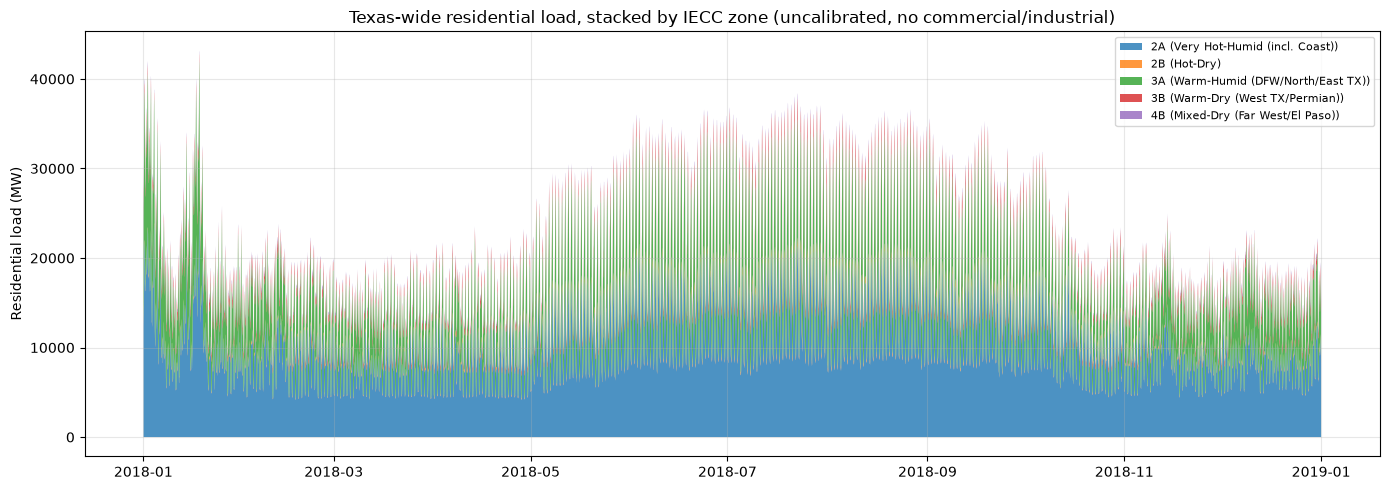

In [6]:
zone_totals = {}
for zone in ZONES:
    df = pd.read_csv(exports_out_dir / f"residential_bus_load_profiles_8760_{zone}.csv", index_col=0, parse_dates=True)
    zone_totals[zone] = df.sum(axis=1) / 1000

zone_totals_df = pd.DataFrame(zone_totals)
zone_totals_df["Statewide_Total"] = zone_totals_df.sum(axis=1)

print("Peak residential load per zone (uncalibrated, MW):")
print(zone_totals_df[ZONES].max().round(1))
print(f"\nStatewide residential peak (sum of all 5 zones): {zone_totals_df['Statewide_Total'].max():,.1f} MW")

fig, ax = plt.subplots(figsize=(14, 5))
bottom = pd.Series(0, index=zone_totals_df.index)
for zone in ZONES:
    ax.fill_between(zone_totals_df.index, bottom, bottom + zone_totals_df[zone], label=f"{zone} ({ZONE_DESC[zone]})", alpha=0.8)
    bottom = bottom + zone_totals_df[zone]
ax.set_ylabel("Residential load (MW)")
ax.set_title("Texas-wide residential load, stacked by IECC zone (uncalibrated, no commercial/industrial)")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 4. Commercial (ComStock): honest R2 across all 5 zones

Same blocked seasonal 4-fold CV methodology as residential, now run for all 15 ComStock
archetypes in every zone (see `commercial_{ZONE}.ipynb`, built once Rafael provided the
statewide ZCTA-to-bus mapping).

In [7]:
cv_com_frames = []
for zone in ZONES:
    df = pd.read_csv(metrics_dir / f"seasonal_cv_comstock_{zone}.csv")
    cv_com_frames.append(df)

cv_com_all = pd.concat(cv_com_frames, ignore_index=True)
pivot_com = cv_com_all.pivot(index="Building_Type", columns="Zone", values="Mean_R2")[ZONES]
pivot_com.loc["Zone mean"] = pivot_com.mean()
pivot_com.round(3)

Zone,2A,2B,3A,3B,4B
Building_Type,,,,,
fullservicerestaurant,0.957,0.876,0.927,0.920,0.963
grocery,0.936,0.739,0.893,-0.100,0.893
hospital,0.965,0.907,0.952,0.943,0.973
largehotel,0.878,0.563,0.772,-1.360,0.680
largeoffice,0.963,0.865,0.927,0.827,0.935
mediumoffice,0.945,0.805,0.886,0.672,0.901
outpatient,0.958,0.904,0.904,0.729,0.914
primaryschool,0.805,0.836,0.744,0.630,0.855
quickservicerestaurant,0.955,0.865,0.913,0.814,0.963


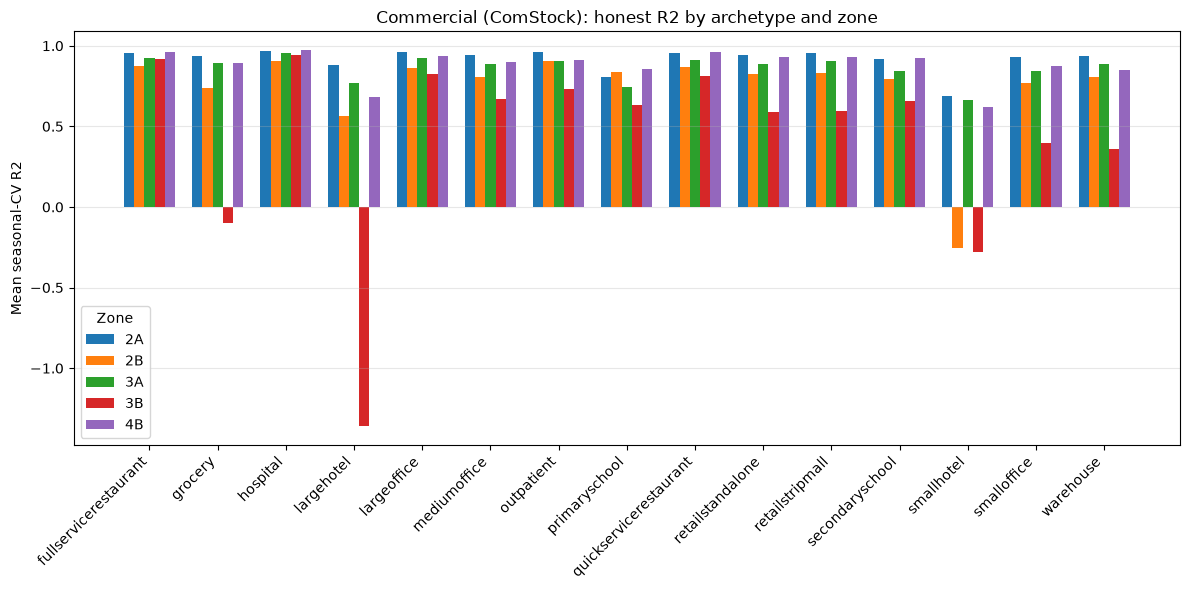

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
btypes_com = cv_com_all["Building_Type"].unique()
x = np.arange(len(btypes_com))
width = 0.15
for i, zone in enumerate(ZONES):
    vals = [cv_com_all[(cv_com_all["Building_Type"] == b) & (cv_com_all["Zone"] == zone)]["Mean_R2"].values[0] for b in btypes_com]
    ax.bar(x + i * width, vals, width, label=zone)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(btypes_com, rotation=45, ha="right")
ax.set_ylabel("Mean seasonal-CV R2")
ax.set_title("Commercial (ComStock): honest R2 by archetype and zone")
ax.legend(title="Zone")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

#### 5. Commercial cross-check: new statewide methodology vs. already-validated Coast pipeline

Same approach as the residential cross-check above: restrict the new zone-2A commercial
reconstruction to buses inside the original 12 Coast counties, and compare shape/magnitude
against the already-validated Coast-only `commercial.ipynb` output (Random Forest, single-station
weather — an older, simpler methodology than the statewide LightGBM + county-blend pipeline, so
this is a cross-check between two different pipelines on the same footprint, not two runs of the
same one).

In [9]:
new_2a_com = pd.read_csv(exports_out_dir / "commercial_bus_load_profiles_8760_2A.csv", index_col=0, parse_dates=True)
new_2a_com.columns = new_2a_com.columns.astype(str)
cols_present_com = [c for c in coast_buses_new if c in new_2a_com.columns]
new_coast_subset_com_mw = new_2a_com[cols_present_com].sum(axis=1) / 1000

old_coast_com = pd.read_csv(exports / "final_comstock_bus_load_profiles_8760_featureeng.csv", index_col=0, parse_dates=True)
old_coast_com_total_mw = old_coast_com.sum(axis=1) / 1000

print(f"New methodology (2A-blend weather), Coast-county subset ({len(cols_present_com)} buses with commercial sqft):")
print(f"  Peak: {new_coast_subset_com_mw.max():,.1f} MW  |  Annual mean: {new_coast_subset_com_mw.mean():,.1f} MW")
print(f"\nOld methodology (Coast-specific weather), original 200-bus Coast pipeline:")
print(f"  Peak: {old_coast_com_total_mw.max():,.1f} MW  |  Annual mean: {old_coast_com_total_mw.mean():,.1f} MW")

common_idx_com = new_coast_subset_com_mw.index.intersection(old_coast_com_total_mw.index)
shape_corr_com = new_coast_subset_com_mw.loc[common_idx_com].corr(old_coast_com_total_mw.loc[common_idx_com])
print(f"\nShape correlation (Pearson) between the two independent methodologies: {shape_corr_com:.4f}")

New methodology (2A-blend weather), Coast-county subset (1505 buses with commercial sqft):
  Peak: 2,606.3 MW  |  Annual mean: 1,291.9 MW

Old methodology (Coast-specific weather), original 200-bus Coast pipeline:
  Peak: 2,534.7 MW  |  Annual mean: 1,245.8 MW

Shape correlation (Pearson) between the two independent methodologies: 0.9993


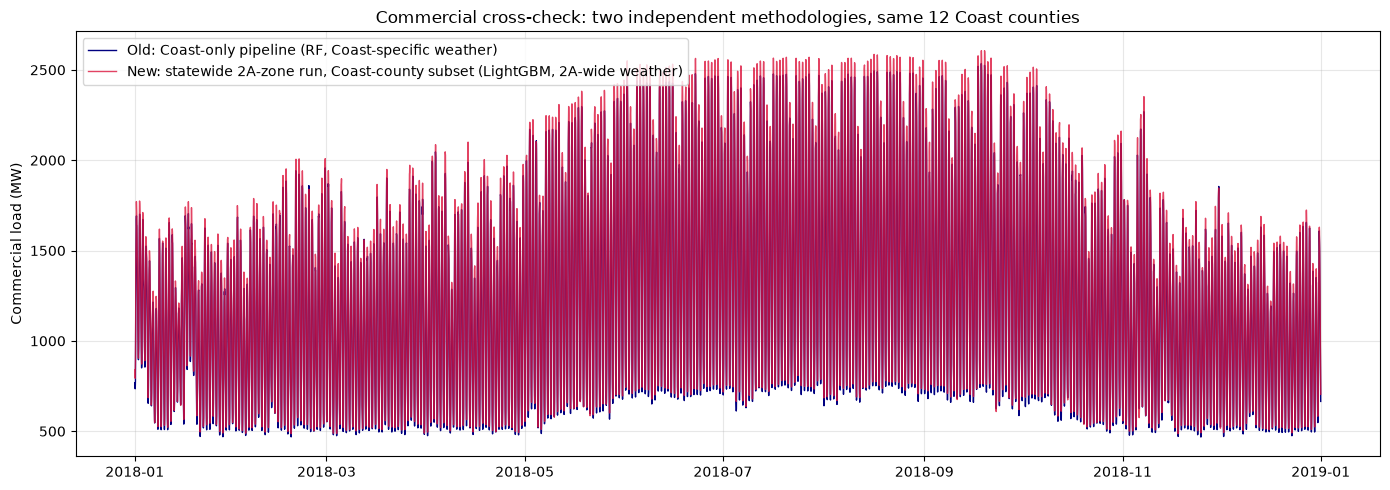

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(old_coast_com_total_mw.index, old_coast_com_total_mw, label="Old: Coast-only pipeline (RF, Coast-specific weather)", color="navy", linewidth=1)
ax.plot(new_coast_subset_com_mw.index, new_coast_subset_com_mw, label="New: statewide 2A-zone run, Coast-county subset (LightGBM, 2A-wide weather)", color="crimson", linewidth=1, alpha=0.8)
ax.set_ylabel("Commercial load (MW)")
ax.set_title("Commercial cross-check: two independent methodologies, same 12 Coast counties")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 6. Texas-wide commercial total (directional only — not ERCOT-validated)

Peak commercial load per zone (uncalibrated, MW):
2A    5305.7
2B     294.1
3A    3343.4
3B     595.0
4B     100.5
dtype: float64

Statewide commercial peak (sum of all 5 zones): 9,434.3 MW


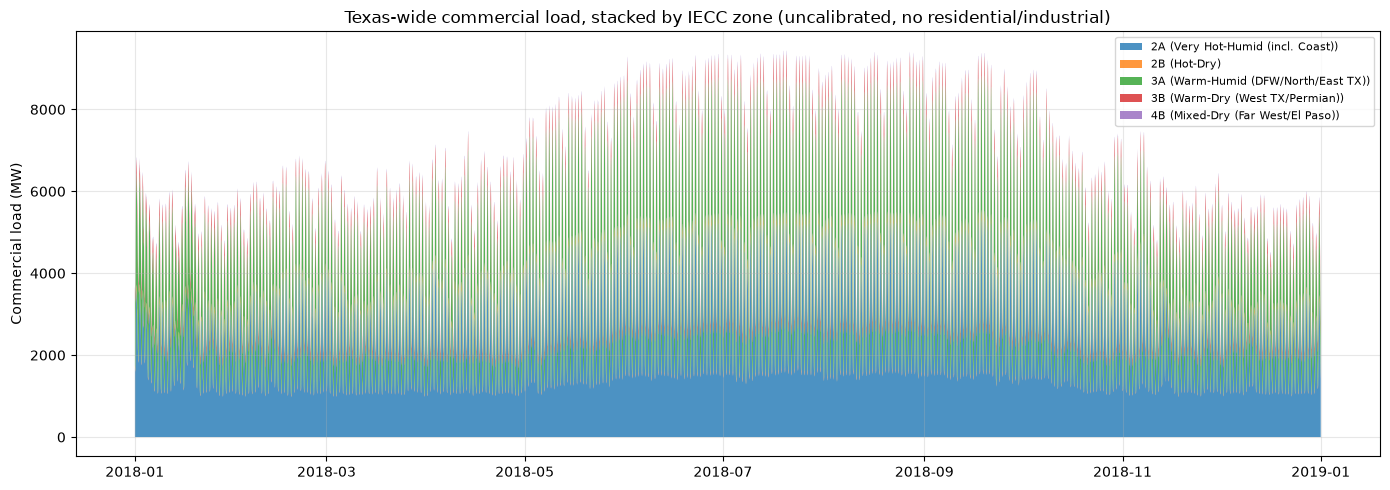

In [11]:
zone_totals_com = {}
for zone in ZONES:
    df = pd.read_csv(exports_out_dir / f"commercial_bus_load_profiles_8760_{zone}.csv", index_col=0, parse_dates=True)
    zone_totals_com[zone] = df.sum(axis=1) / 1000

zone_totals_com_df = pd.DataFrame(zone_totals_com)
zone_totals_com_df["Statewide_Total"] = zone_totals_com_df.sum(axis=1)

print("Peak commercial load per zone (uncalibrated, MW):")
print(zone_totals_com_df[ZONES].max().round(1))
print(f"\nStatewide commercial peak (sum of all 5 zones): {zone_totals_com_df['Statewide_Total'].max():,.1f} MW")

fig, ax = plt.subplots(figsize=(14, 5))
bottom = pd.Series(0, index=zone_totals_com_df.index)
for zone in ZONES:
    ax.fill_between(zone_totals_com_df.index, bottom, bottom + zone_totals_com_df[zone], label=f"{zone} ({ZONE_DESC[zone]})", alpha=0.8)
    bottom = bottom + zone_totals_com_df[zone]
ax.set_ylabel("Commercial load (MW)")
ax.set_title("Texas-wide commercial load, stacked by IECC zone (uncalibrated, no residential/industrial)")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 7. Texas-wide residential + commercial total (directional only — no industrial, no ERCOT calibration)

Statewide residential+commercial peak: 49,197.6 MW
  of which residential: 43,161.1 MW, commercial: 9,434.3 MW


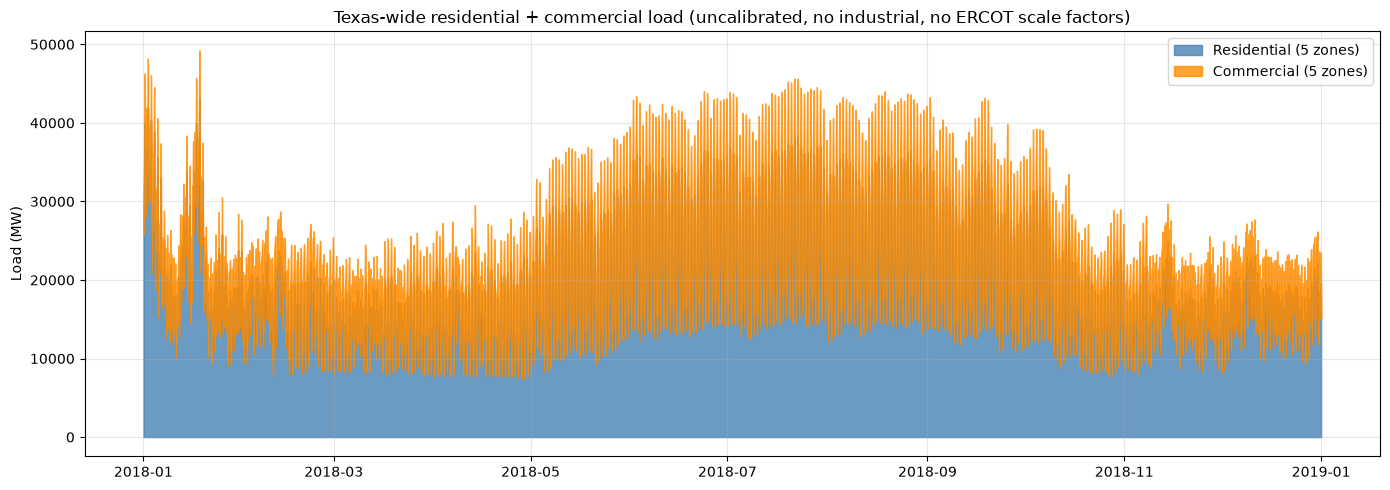

In [12]:
combined_total = zone_totals_df["Statewide_Total"] + zone_totals_com_df["Statewide_Total"]
print(f"Statewide residential+commercial peak: {combined_total.max():,.1f} MW")
print(f"  of which residential: {zone_totals_df['Statewide_Total'].max():,.1f} MW, commercial: {zone_totals_com_df['Statewide_Total'].max():,.1f} MW")

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(zone_totals_df.index, 0, zone_totals_df["Statewide_Total"], label="Residential (5 zones)", alpha=0.8, color="steelblue")
ax.fill_between(zone_totals_com_df.index, zone_totals_df["Statewide_Total"], combined_total, label="Commercial (5 zones)", alpha=0.8, color="darkorange")
ax.set_ylabel("Load (MW)")
ax.set_title("Texas-wide residential + commercial load (uncalibrated, no industrial, no ERCOT scale factors)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Summary and next steps

**Delivered**: honest, leakage-free residential AND commercial reconstructions for all 5 Texas
IECC climate zones (254 counties, 3,426 buses), using the same best-practice pipeline validated
on Coast (county-weighted weather blend, cyclical + lag features, LightGBM, blocked seasonal
4-fold CV). Commercial reuses the original Coast `commercial.ipynb` employment methodology
(CBP/ZBP employment by NAICS -> `get_comstock_type()` -> CBECS sqft/employee factors), generalized
statewide via `zcta_bus_mapping_tx_final.csv` (processed into `zcta_to_zone.csv` in
`00_zone_mapping.ipynb`, with a nearest-known-bus fallback for the ~28% of ZCTAs whose nearest
bus never received a tract assignment). Two new geography bugs found and fixed in the process
(same class as the original weather-station bug, both caught by checking a suspicious diagnostic
number rather than trusting a silent join): the 2020-vs-2010 Census tract vintage mismatch found
while building the residential zones, and (implicitly handled by the fallback above) the ZCTA/tract
nearest-bus-join mismatch found while building the ZCTA zone assignment.

**Zone difficulty ranking** (honest seasonal-CV R2, both residential and commercial): 2A (Coast's
own climate, hot-humid) is clearly the easiest to model; the drier/more continental zones (2B, 3B,
4B) are meaningfully harder — plausibly a mix of a more complex weather-load relationship (real
heating seasons, not just cooling-dominated) and smaller sample sizes. Commercial archetypes with
sparse/lumpy demand (largehotel, smallhotel) are the weakest performers across every zone, same
pattern as Coast.

**Open items**:
- Full ERCOT validation, per-zone or statewide — still needs an industrial baseline for every
  zone, not just Coast's flat 4500 MW assumption (which is Coast-specific and should not be reused
  as-is elsewhere). ERCOT's own load-history split is by weather zone (Coast, North, West, ...),
  not by IECC climate zone, so this needs its own crosswalk before a real statewide ERCOT
  comparison is possible.
- Per-bus or per-county (rather than per-zone) weather granularity — the cross-check above shows
  a zone-wide weather blend measurably changes results versus a locally-tuned one for the same
  sub-region; this is the same spatial-diversity limitation flagged for Coast, now visible at zone
  scale too, for both residential and commercial.
- Industrial load, data-driven rather than Coast's flat assumption, is the main remaining gap
  before a genuine statewide ERCOT-comparable reconstruction.